In [29]:
import sys

print(sys.executable)

/home/robin/projets/projet_MLops/Supply-Chain-MLOps/.venv/bin/python


# Import des données et description générale

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as ss

In [31]:
df = pd.read_csv('../data/raw/avis_40k.csv', sep=';', header=0)
print("chargement des données et description rapide")

display(df.head())
display(df.info())
display(df.describe())

chargement des données et description rapide


,auteur,note,titre,commentaire,date_experience,date_avis,url,texteServiceReply,dateServiceReply,dataServiceReply
0,FREDERIC (Bordeaux),4,Produit conforme,Produit conforme. La description du contenue e...,"February 13, 2026",A day ago,https://www.trustpilot.com/review/oscaro.com,NaN,NaN,NaN
1,Patrice,5,Comportement professionnel,NaN,"February 11, 2026",3 days ago,https://www.trustpilot.com/review/oscaro.com,NaN,NaN,NaN
2,Client daniel,4,R.A.S,..............R.A.S.........,"January 31, 2026",3 days ago,https://www.trustpilot.com/review/oscaro.com,NaN,NaN,NaN
3,Derek Mcmillan,5,Excellent.,NaN,"February 4, 2026","Feb 4, 2026",https://www.trustpilot.com/review/oscaro.com,Reply from Oscaro,"Feb 5, 2026","Bonjour Derek, Je vous remercie pour votre ret..."
4,GM,4,Tres bien mais attention bien scotcher…,Tres bien mais attention bien scotcher les col...,"January 30, 2026","Feb 1, 2026",https://www.trustpilot.com/review/oscaro.com,Reply from Oscaro,"Feb 3, 2026","Bonjour Grégoire , Je vous remercie pour votre..."


<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   auteur             40000 non-null  str  
 1   note               40000 non-null  int64
 2   titre              40000 non-null  str  
 3   commentaire        36225 non-null  str  
 4   date_experience    40000 non-null  str  
 5   date_avis          40000 non-null  str  
 6   url                40000 non-null  str  
 7   texteServiceReply  33146 non-null  str  
 8   dateServiceReply   33146 non-null  str  
 9   dataServiceReply   33146 non-null  str  
dtypes: int64(1), str(9)
memory usage: 22.2 MB


None

,note
count,40000.00000
mean,4.02915
std,1.40819
min,1.00000
25%,3.00000
50%,5.00000
75%,5.00000
max,5.00000


# Définition du problème

* Avant toute chose il est bon de définir **Quelle est la cible ?**. Pour ce projet, l'objectif est de catégoriser les avis utilisateurs de manière automatique, c'est donc un problème de clustering. Il n'y a pas de variable cible comme dans un cas classique de classification supervisée. Il faudra néanmoins réfléchir par la suite aux indicateurs pertinents pouvant être utilisés pour estimer la qualité des clusters produits.
* La variable utilisée pour ce clustering est la variable **commentaire** correspondant aux avis utilisateurs. Ces avis sont issus d'un scrapping de TrustePilot pour 40k avis concernant l'entreprise Oscaro. Les autres variables seront utiliser pour l'exploration des données.

# Traitement des NA et suppression des variables inutiles

traitement des NaN
3775
pourcentage Na parmi les avis: 9.4375
            auteur  note                           titre commentaire  \
1          Patrice     5      Comportement professionnel         NaN   
3   Derek Mcmillan     5                      Excellent.         NaN   
7     Masnou Bruno     5      Super.....................         NaN   
16          Anouar     5                  Good good good         NaN   
19           Aslan     1  Nulle je déconseille set sites         NaN   

      date_experience     date_avis  \
1   February 11, 2026    3 days ago   
3    February 4, 2026   Feb 4, 2026   
7    January 15, 2026  Jan 16, 2026   
16  December 15, 2025  Dec 17, 2025   
19  November 27, 2025  Nov 27, 2025   

                                             url  texteServiceReply  \
1   https://www.trustpilot.com/review/oscaro.com                NaN   
3   https://www.trustpilot.com/review/oscaro.com  Reply from Oscaro   
7   https://www.trustpilot.com/review/oscaro.com  Reply f

Text(0.5, 1.0, 'Proportion de NaN parmi les avis clients')

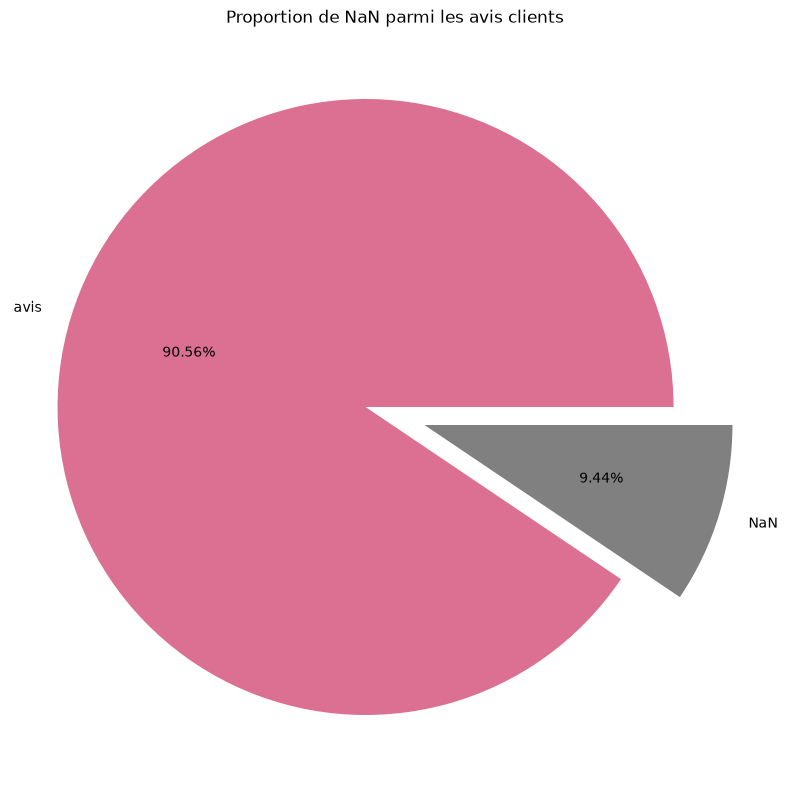

In [32]:
print('traitement des NaN')

print(df['commentaire'].isna().sum())
print('pourcentage Na parmi les avis:', df['commentaire'].isna().sum()/len(df['commentaire'])*100)
print(df[df['commentaire'].isna()].head())


plt.figure(figsize=(10,10))
plt.pie(df["commentaire"].isna().value_counts(normalize=True),
            labels=['avis', 'NaN'],
            explode=[0.1, 0.1],
            autopct="%0.2f%%",
            colors=["palevioletred", "grey"])
plt.title('Proportion de NaN parmi les avis clients')

In [33]:
df['commentaire'] = df['commentaire'].fillna(df['titre']) # remplacement na par titre
df[['commentaire', 'auteur', 'date_avis']] = df[['commentaire', 'auteur', 'date_avis']].drop_duplicates() # suppression des duplicats
df = df.drop('date_avis', axis=1) # suppression date avis, on garde uniquement date experience
df = df.drop('texteServiceReply', axis=1) # suppression de la variable car n'apporte pas d'info
df = df.drop('url', axis = 1)
df = df.drop('dateServiceReply', axis = 1)

display(df.info())
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   auteur            39948 non-null  str  
 1   note              40000 non-null  int64
 2   titre             40000 non-null  str  
 3   commentaire       39948 non-null  str  
 4   date_experience   40000 non-null  str  
 5   dataServiceReply  33146 non-null  str  
dtypes: int64(1), str(5)
memory usage: 17.2 MB


None

,auteur,note,titre,commentaire,date_experience,dataServiceReply
0,FREDERIC (Bordeaux),4,Produit conforme,Produit conforme. La description du contenue e...,"February 13, 2026",NaN
1,Patrice,5,Comportement professionnel,Comportement professionnel,"February 11, 2026",NaN
2,Client daniel,4,R.A.S,..............R.A.S.........,"January 31, 2026",NaN
3,Derek Mcmillan,5,Excellent.,Excellent.,"February 4, 2026","Bonjour Derek, Je vous remercie pour votre ret..."
4,GM,4,Tres bien mais attention bien scotcher…,Tres bien mais attention bien scotcher les col...,"January 30, 2026","Bonjour Grégoire , Je vous remercie pour votre..."


# Traitement de la langue dans le corpus d'avis

In [34]:
from langdetect import detect
from langdetect import DetectorFactory
DetectorFactory.seed = 34

def to_detect(text_i): # détection de la langue
    try :
        return detect(text_i)
    except:
        return ('NA')

df["lang"] = df["commentaire"].apply(lambda x: to_detect(x))
print(df['lang'].value_counts())
print(df['lang'].describe(include='O'))

lang
fr    38261
ca      360
es      316
en      289
de      128
it      123
pt      122
ro      105
NA       78
nl       47
vi       25
lv       18
id       16
af       16
hu       13
sk       11
et       10
fi        9
so        7
sv        7
pl        6
tl        6
da        5
lt        4
sq        4
tr        3
no        3
cy        3
bg        1
ru        1
cs        1
sw        1
hr        1
Name: count, dtype: int64
count     40000
unique       33
top          fr
freq      38261
Name: lang, dtype: object


In [35]:
display(df.info())
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   auteur            39948 non-null  str  
 1   note              40000 non-null  int64
 2   titre             40000 non-null  str  
 3   commentaire       39948 non-null  str  
 4   date_experience   40000 non-null  str  
 5   dataServiceReply  33146 non-null  str  
 6   lang              40000 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.5 MB


None

,auteur,note,titre,commentaire,date_experience,dataServiceReply,lang
0,FREDERIC (Bordeaux),4,Produit conforme,Produit conforme. La description du contenue e...,"February 13, 2026",NaN,fr
1,Patrice,5,Comportement professionnel,Comportement professionnel,"February 11, 2026",NaN,fr
2,Client daniel,4,R.A.S,..............R.A.S.........,"January 31, 2026",NaN,hu
3,Derek Mcmillan,5,Excellent.,Excellent.,"February 4, 2026","Bonjour Derek, Je vous remercie pour votre ret...",ca
4,GM,4,Tres bien mais attention bien scotcher…,Tres bien mais attention bien scotcher les col...,"January 30, 2026","Bonjour Grégoire , Je vous remercie pour votre...",fr


In [36]:
df = df[df["lang"] == "fr"] # on conserve uniquement les avis en français
df = df.dropna(subset=['commentaire'])
df.head()
df.info()

<class 'pandas.DataFrame'>
Index: 38261 entries, 0 to 39999
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   auteur            38261 non-null  str  
 1   note              38261 non-null  int64
 2   titre             38261 non-null  str  
 3   commentaire       38261 non-null  str  
 4   date_experience   38261 non-null  str  
 5   dataServiceReply  31736 non-null  str  
 6   lang              38261 non-null  str  
dtypes: int64(1), str(6)
memory usage: 17.3 MB


# Création de nouvelles variables pour la visualisation temporelle

In [43]:
# Trier chronologiquement les avis
df["date_to_sort"] = pd.to_datetime(
    df["date_experience"],
    format="%B %d, %Y",
)

df = df.sort_values("date_to_sort").reset_index(drop=True)

# Entraînement initial : 60 %
df_train = df.iloc[:24000].copy()

# Référence du monitoring : 10 %
df_reference = df.iloc[24000:28000].copy()

# Production simulée : 20 %
df_production = df.iloc[28000:36000].copy()

# Évaluation finale : 10 %
df_test = df.iloc[36000:].copy()


date_experience_month
5     0.130708
11    0.104336
8     0.102925
6     0.100991
10    0.098691
7     0.098037
1     0.086407
12    0.086171
9     0.074018
4     0.065367
2     0.045529
3     0.006822
Name: proportion, dtype: float64

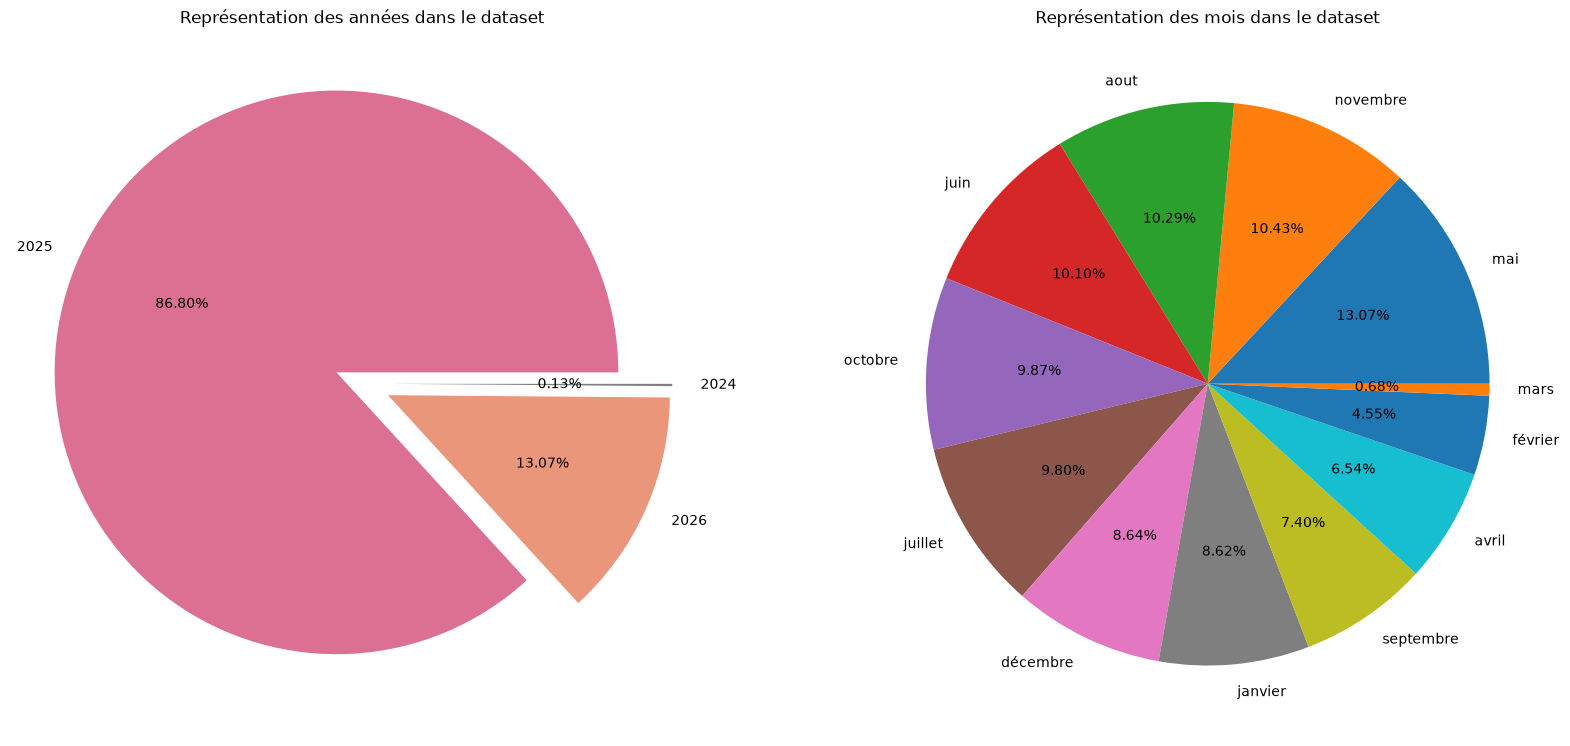

In [44]:
month_to_number = {'January' : 1, 'February' : 2, 'March' : 3, 'April' : 4, 'May' : 5, 'June' : 6, 'July' : 7, 'August' : 8, 'September' : 9, 'October' : 10, 'November' : 11, 'December' : 12}

df['date_experience_year'] = df['date_experience'].str[-4:] # transformation variable date_experience en 2 variables: année et mois
df['date_experience_month'] = df['date_experience'].replace(month_to_number, regex=True).astype(int)
df['date_experience_year'] = df['date_experience_year'].astype(int)
df = df.drop('date_experience', axis=1)

# création comm_reply : fusion avis + réponse entreprise
df['comm_reply'] = np.where(df['dataServiceReply'].isna() == False, df['commentaire'] + df['dataServiceReply'], df['commentaire'])

# création length_comm : taille de l'avis
df['length_comm'] = df['commentaire'].apply(lambda x: len(x))

plt.figure(figsize=(20,10))

plt.subplot(121)

plt.pie(df["date_experience_year"].value_counts(normalize=True),
            labels=['2025', '2026', '2024'],
            explode=[0.1, 0.1, 0.1],
            autopct="%0.2f%%",
            colors=["palevioletred", "darksalmon", "grey"])
plt.title('Représentation des années dans le dataset')

plt.subplot(122)

plt.pie(df["date_experience_month"].value_counts(normalize=True),
            labels=['mai', 'novembre', 'aout', 'juin', 'octobre', 'juillet', 'décembre', 'janvier', 'septembre', 'avril', 'février', 'mars'],
            #explode=[0.1, 0.1, 0.1],
            autopct="%0.2f%%")
            #colors=["palevioletred", "darksalmon", "grey"])
plt.title('Représentation des mois dans le dataset')


df["date_experience_month"].value_counts(normalize=True)

# Distribution des notes et de la taille des commentaires

Text(0.5, 1.0, 'taille médiane des commentaires en fonction de la note')

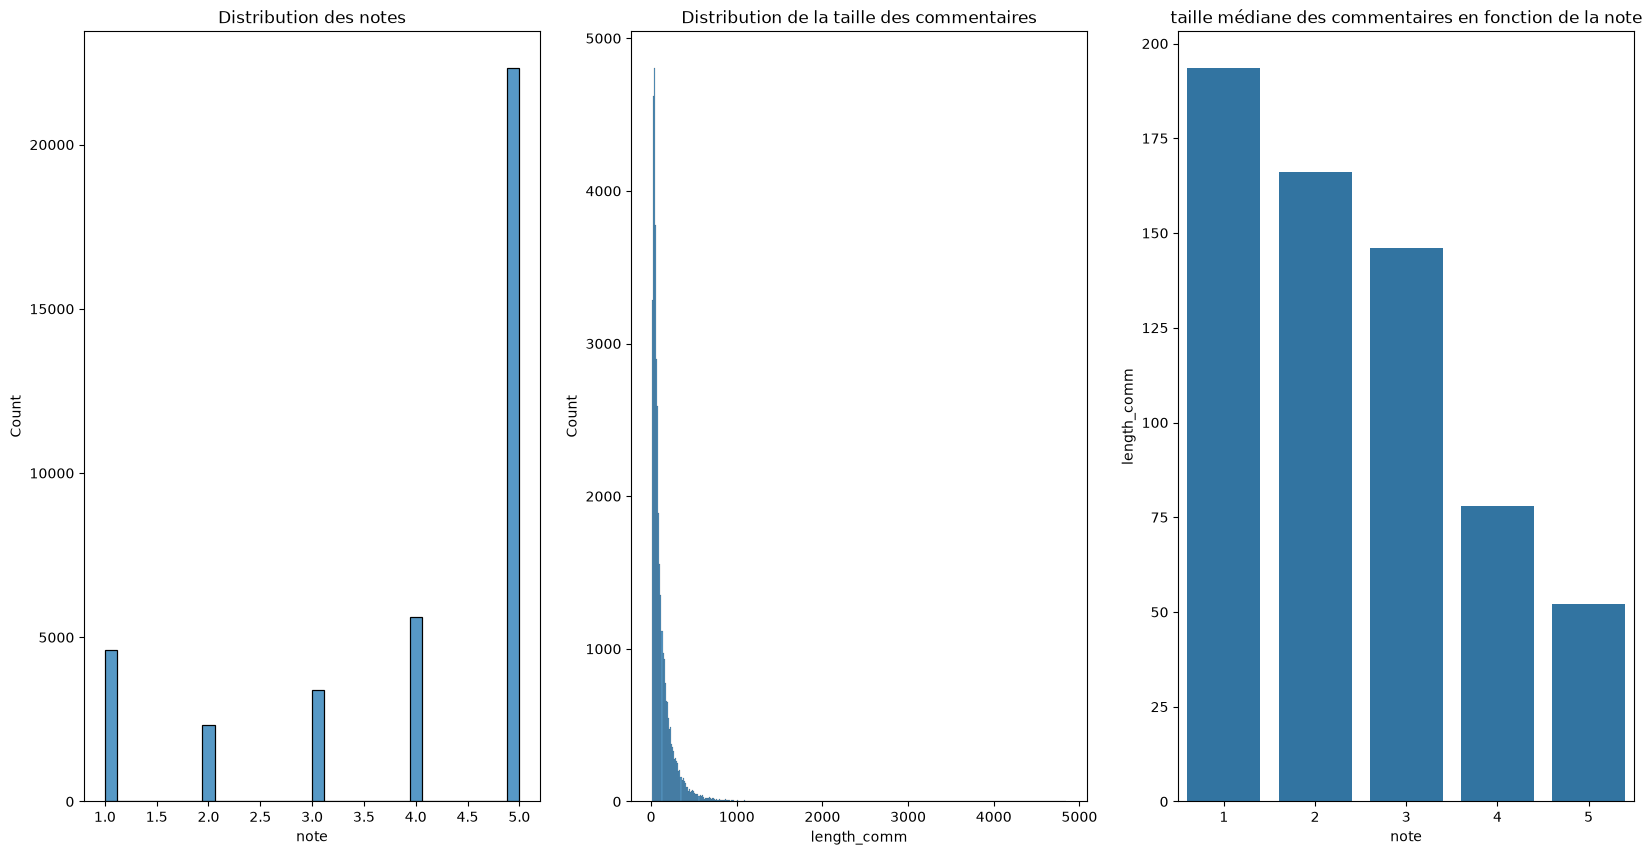

In [45]:
plt.figure(figsize=(20,10))

plt.subplot(131)

sns.histplot(df['note'])
plt.title('Distribution des notes')

plt.subplot(132)

sns.histplot(df['length_comm'])
plt.title('Distribution de la taille des commentaires')

plt.subplot(133)

sns.barplot(data= df[['note','length_comm']].groupby('note').median(), x='note', y='length_comm')
plt.title('taille médiane des commentaires en fonction de la note')

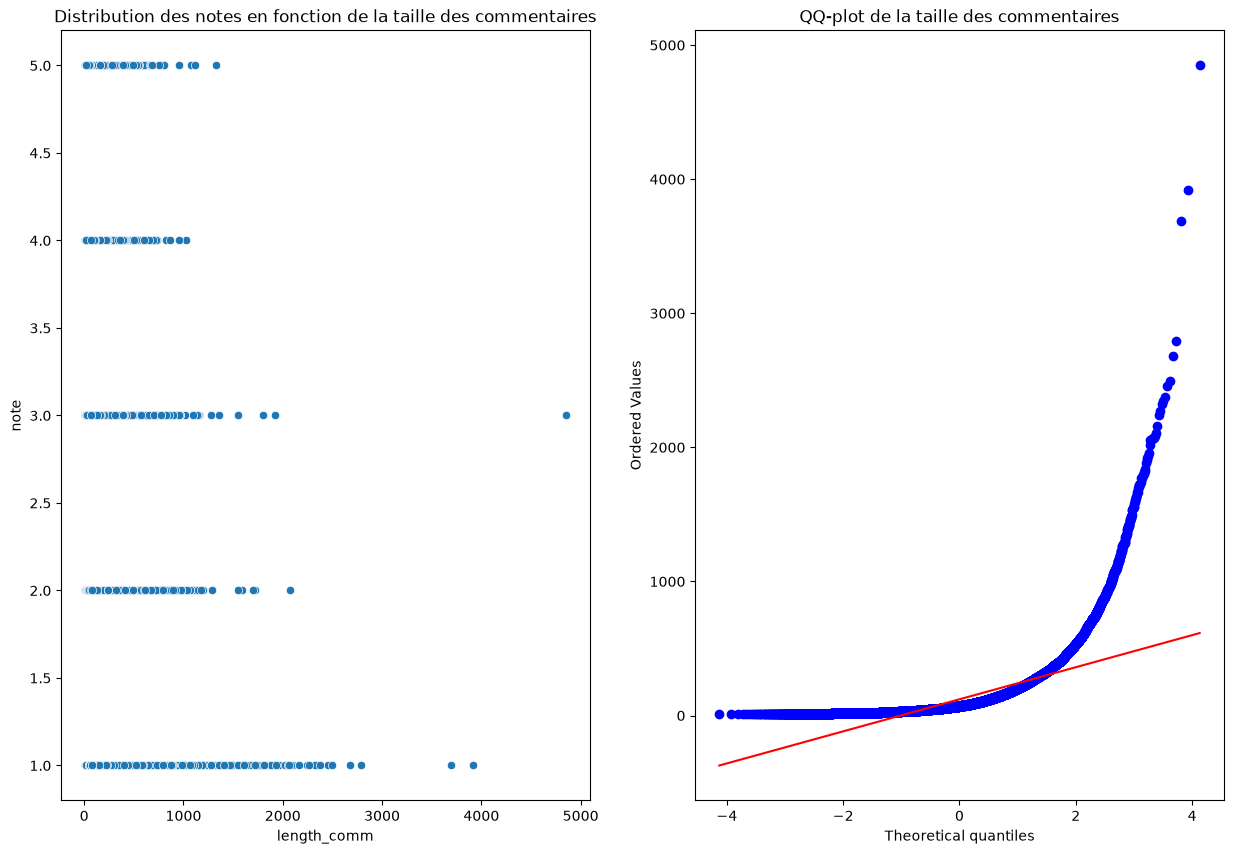

                note  length_comm
note         1.00000     -0.46309
length_comm -0.46309      1.00000
normalité des données, shapiro's p.value: 4.306662496637658e-75
pearson correlation coef: -0.46308957127179995
pearson correlation p.value: 0.0
kendall correlation coef: -0.3734948642650401
kendall correlation p.value: 0.0


In [46]:
plt.figure(figsize=(15,10))
plt.subplot(1,2,1)
sns.scatterplot(x=df['length_comm'], y=df['note'])
plt.title('Distribution des notes en fonction de la taille des commentaires')
plt.subplot(122)
ss.probplot(df['length_comm'], plot=plt)
plt.title('QQ-plot de la taille des commentaires')
plt.show()



#plt.subplot(223)
#sns.lmplot(x='length_comm', y='note', data=df, )

print(df[['note', 'length_comm']].corr())

print('normalité des données, shapiro\'s p.value:', ss.shapiro(df['length_comm'].head(5000))[1])
print('pearson correlation coef:', ss.pearsonr(df['length_comm'], df['note'])[0])
print('pearson correlation p.value:', ss.pearsonr(df['length_comm'], df['note'])[1])
print('kendall correlation coef:', ss.kendalltau(df['length_comm'], df['note'])[0])
print('kendall correlation p.value:', ss.kendalltau(df['length_comm'], df['note'])[1])

# Export des données

In [47]:
df_train.to_csv('../data/raw/avis_24k_train.csv') # entrainement initial
df_reference.to_csv('../data/raw/avis_4k_reference.csv') # référence monitoring
df_production.to_csv('../data/raw/avis_8k_production.csv') # production simulée
df_test.to_csv('../data/raw/avis_3k_test.csv') # test final

# Wordcloud

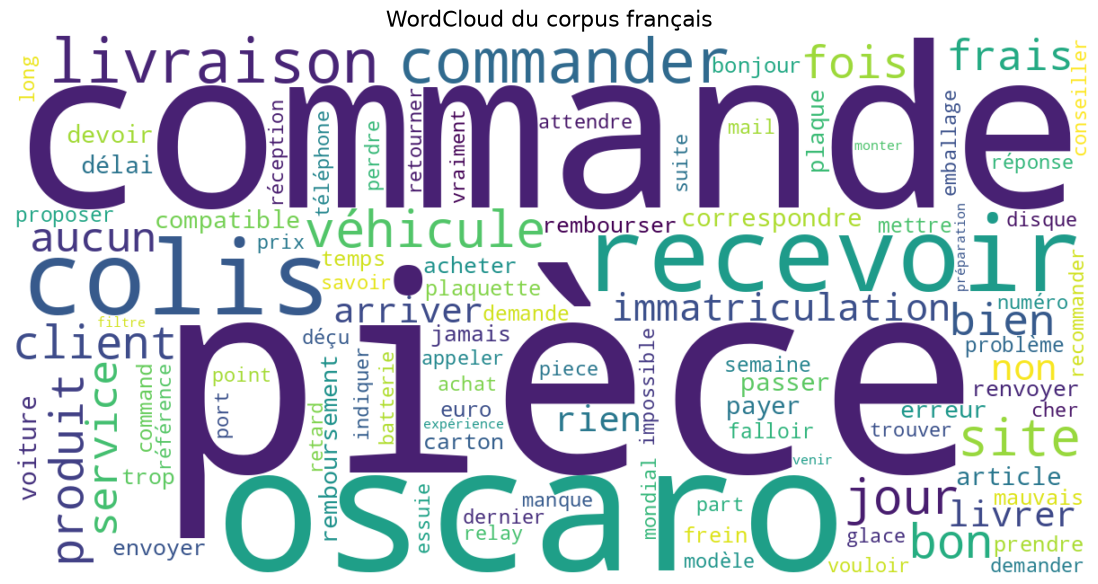

In [48]:
import spacy
from collections import Counter
from wordcloud import WordCloud

# Chargement du modèle linguistique français
nlp = spacy.load("fr_core_news_sm")

# Stopwords supplémentaires, adaptés au corpus
custom_stopwords = {
    "être", "avoir", "faire", "dire",
    "aller", "voir", "pouvoir"
}

def preprocess_text(text):
    """
    Nettoie et lemmatise un texte français.
    Retourne une liste de tokens.
    """
    doc = nlp(text.lower())

    tokens = [
        token.lemma_.lower()
        for token in doc
        if not token.is_stop
        and not token.is_punct
        and not token.is_space
        and not token.like_url
        and not token.like_email
        and token.is_alpha
        and len(token.lemma_) > 2
        and token.lemma_.lower() not in custom_stopwords
    ]

    return tokens


# Exemple de corpus
texts = df[df['note']==1]['commentaire']
# Prétraitement de tous les documents
tokens = []

for text in texts:
    tokens.extend(preprocess_text(text))

# Calcul des fréquences
frequencies = Counter(tokens)

# Génération du WordCloud
wc = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100,
    collocations=False,
    random_state=42
).generate_from_frequencies(frequencies)

# Visualisation
plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud du corpus français", fontsize=16)
plt.show()